# A02 · Parte 2 — EDA de la resistencia a la compresión del hormigón  ·  *Versión resuelta para estudio*

**Autor:** Claude

**Asignatura:** TPIA — Experto Universitario

> 📘 **Cómo usar este cuaderno.** Mantiene la estructura de tu entrega (secciones 1–6). Las celdas 📘 son **notas de estudio**
> (qué se hace, por qué y qué mirar en la salida); los bloques "**Interpretación**" son lo que iría en el informe.
> La diferencia clave con la Parte 1: aquí **todas las variables son numéricas** y el problema es de **regresión**,
> así que las herramientas cambian (estadísticos descriptivos, histogramas, boxplots, dispersión y correlaciones).

## 1. Introducción y objetivos

El dataset *Concrete Compressive Strength* (UCI, I-Cheng Yeh, 2007) recoge **1030 ensayos de laboratorio** sobre mezclas de
hormigón. Para cada ensayo se conocen las cantidades de los **7 componentes** de la mezcla (kg por m³: cemento, escoria de alto
horno, ceniza volante, agua, superplastificante, árido grueso y árido fino), la **edad** de la probeta en días (1–365) y la
**resistencia a la compresión** obtenida (MPa), que es la variable objetivo. Según `Concrete_Readme.txt`, la resistencia es
*una función altamente no lineal de la edad y de los ingredientes*.

**Objetivos del EDA**

1. Inspeccionar la estructura y los estadísticos básicos (medias, varianzas, rangos, forma de las distribuciones).
2. Verificar la calidad de los datos (nulos, duplicados, valores atípicos, coherencia física).
3. Analizar la distribución de cada variable.
4. Estudiar la relación (lineal y monótona) de cada componente y de la edad con la resistencia, así como las relaciones entre
   componentes.
5. Extraer conclusiones útiles para un posterior modelo de regresión.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.precision", 2)
pd.set_option("display.width", 200)

## 2. Carga y comprensión de los datos

Los nombres originales del Excel son largos; se renombran a nombres cortos siguiendo el orden de `Concrete_Readme.txt`.

> 📘 El fichero es `.xls` (Excel antiguo): `pd.read_excel` necesita el paquete **`xlrd`** (`pip install xlrd`).
> Antes de renombrar, imprime `df.columns` para comprobar que el orden coincide con el del Readme.

In [2]:
df = pd.read_excel("../datos/concrete/Concrete_Data.xls")
print("Columnas originales:")
for c in df.columns:
    print("  ", repr(c))

df.columns = ["cement", "slag", "fly_ash", "water", "superplasticizer",
              "coarse_agg", "fine_agg", "age", "strength"]
df.head()

Columnas originales:
   'Cement (component 1)(kg in a m^3 mixture)'
   'Blast Furnace Slag (component 2)(kg in a m^3 mixture)'
   'Fly Ash (component 3)(kg in a m^3 mixture)'
   'Water  (component 4)(kg in a m^3 mixture)'
   'Superplasticizer (component 5)(kg in a m^3 mixture)'
   'Coarse Aggregate  (component 6)(kg in a m^3 mixture)'
   'Fine Aggregate (component 7)(kg in a m^3 mixture)'
   'Age (day)'
   'Concrete compressive strength(MPa, megapascals) '


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [3]:
df.shape

(1030, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1030 non-null   float64
 1   slag              1030 non-null   float64
 2   fly_ash           1030 non-null   float64
 3   water             1030 non-null   float64
 4   superplasticizer  1030 non-null   float64
 5   coarse_agg        1030 non-null   float64
 6   fine_agg          1030 non-null   float64
 7   age               1030 non-null   int64  
 8   strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [5]:
# Diccionario de variables (a partir de Concrete_Readme.txt)
diccionario = pd.DataFrame({
    "descripción": ["Cemento", "Escoria de alto horno", "Ceniza volante", "Agua", "Superplastificante",
                    "Árido grueso", "Árido fino", "Edad de la probeta", "Resistencia a la compresión"],
    "unidad": ["kg/m³"] * 7 + ["días", "MPa"],
    "rol": ["entrada"] * 8 + ["objetivo"],
    "dtype": df.dtypes.astype(str).values,
}, index=df.columns)
diccionario

,descripción,unidad,rol,dtype
cement,Cemento,kg/m³,entrada,float64
slag,Escoria de alto horno,kg/m³,entrada,float64
fly_ash,Ceniza volante,kg/m³,entrada,float64
water,Agua,kg/m³,entrada,float64
superplasticizer,Superplastificante,kg/m³,entrada,float64
coarse_agg,Árido grueso,kg/m³,entrada,float64
fine_agg,Árido fino,kg/m³,entrada,float64
age,Edad de la probeta,días,entrada,int64
strength,Resistencia a la compresión,MPa,objetivo,float64


**Interpretación**

El dataset tiene **1030 observaciones y 9 variables, todas numéricas continuas** (`float64`, salvo `age`, que es entera).
Hay 8 variables de entrada (7 componentes de la mezcla en kg/m³ y la edad en días) y una variable objetivo continua,
`strength` (MPa), por lo que el problema es de **regresión**. Todas las unidades de los componentes son iguales, lo que
permite compararlos directamente y construir proporciones entre ellos.

### 2.1 Inspección estadística inicial (medias, varianzas, rangos)

> 📘 `describe()` da media, desviación, mínimo, cuartiles y máximo. Le añadimos lo que pide el enunciado y lo que ayuda a
> interpretar: **varianza**, **rango**, **coeficiente de variación** (CV = σ/μ, compara dispersión entre variables con escalas
> distintas), **asimetría** (*skew*: 0 simétrica, > 0 cola a la derecha) y **curtosis** (> 0 colas pesadas) y el **% de ceros**.

In [6]:
desc = df.describe().T
desc["var"] = df.var()
desc["rango"] = desc["max"] - desc["min"]
desc["CV"] = desc["std"] / desc["mean"]
desc["asimetría"] = df.skew()
desc["curtosis"] = df.kurt()
desc["% ceros"] = (df == 0).mean() * 100
desc[["mean", "std", "var", "min", "25%", "50%", "75%", "max", "rango", "CV", "asimetría", "curtosis", "% ceros"]]

,mean,std,var,min,25%,50%,75%,max,rango,CV,asimetría,curtosis,% ceros
cement,281.17,104.51,10921.74,102.00,192.38,272.90,350.00,540.0,438.00,0.37,0.51,-0.52,0.00
slag,73.90,86.28,7444.08,0.00,0.00,22.00,142.95,359.4,359.40,1.17,0.80,-0.51,45.24
fly_ash,54.19,64.00,4095.55,0.00,0.00,0.00,118.27,200.1,200.10,1.18,0.54,-1.33,54.95
water,181.57,21.36,456.06,121.75,164.90,185.00,192.00,247.0,125.25,0.12,0.07,0.12,0.00
superplasticizer,6.20,5.97,35.68,0.00,0.00,6.35,10.16,32.2,32.20,0.96,0.91,1.41,36.80
coarse_agg,972.92,77.75,6045.66,801.00,932.00,968.00,1029.40,1145.0,344.00,0.08,-0.04,-0.60,0.00
fine_agg,773.58,80.18,6428.10,594.00,730.95,779.51,824.00,992.6,398.60,0.10,-0.25,-0.10,0.00
age,45.66,63.17,3990.44,1.00,7.00,28.00,56.00,365.0,364.00,1.38,3.27,12.17,0.00
strength,35.82,16.71,279.08,2.33,23.71,34.44,46.14,82.6,80.27,0.47,0.42,-0.31,0.00


**Interpretación**

- **Resistencia (`strength`)**: media de **35,8 MPa** (mediana 34,4) con desviación de 16,7 MPa y un rango muy amplio,
  de 2,3 a 82,6 MPa. Ligera asimetría positiva (0,42): la mayoría de mezclas están en resistencias medias, con una cola de
  hormigones de alta resistencia.
- **Cemento** es el componente aglomerante principal: media de 281 kg/m³ (102–540), siempre presente.
- **Escoria (`slag`), ceniza volante (`fly_ash`) y superplastificante** tienen CV ≈ 1 o superior y una gran proporción de
  **ceros** (45 %, 55 % y 37 % respectivamente). No son variables continuas "normales": son **aditivos opcionales**, y su
  distribución es una mezcla de "no se usa" (0) y "se usa en cierta cantidad".
- **Agua y áridos** son los componentes más estables (CV ≈ 0,08–0,12): varían relativamente poco entre mezclas. Los áridos son,
  en masa, la mayor parte de la mezcla (≈ 970 y 775 kg/m³).
- **Edad (`age`)**: muy asimétrica (asimetría 3,3; curtosis 12,2). La media (45,7 días) está muy por encima de la mediana
  (28 días), señal de que unos pocos ensayos a 180–365 días tiran de la media.
- **Las escalas son muy distintas** (superplastificante 0–32 kg/m³ frente a árido grueso 801–1145 kg/m³), por lo que en el
  modelado será necesario **estandarizar** las variables para modelos sensibles a la escala.

## 3. Limpieza de datos

> 📘 Checklist: (1) nulos; (2) duplicados; (3) **coherencia física** (no puede haber cantidades negativas, edad 0, ni una masa
> total por m³ absurda: un hormigón pesa ~2200–2600 kg/m³); (4) **atípicos** con el criterio IQR
> (valor < Q1 − 1,5·IQR o > Q3 + 1,5·IQR). Un atípico **no se borra por defecto**: primero se decide si es un error o un valor
> extremo pero real.

In [7]:
print("Nulos por columna:")
print(df.isna().sum().to_string())

print(f"\nFilas duplicadas: {df.duplicated().sum()}  (filas implicadas: {df.duplicated(keep=False).sum()})")
print("Valores negativos:", (df < 0).sum().sum())
print("Edad mínima:", df["age"].min(), "días")

Nulos por columna:
cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_agg          0
fine_agg            0
age                 0
strength            0

Filas duplicadas: 25  (filas implicadas: 36)
Valores negativos: 0
Edad mínima: 1 días


In [8]:
# Inspección de los duplicados: ¿son la misma mezcla, misma edad y misma resistencia?
cols = list(df.columns)
dups = df[df.duplicated(keep=False)]
dups.groupby(cols).size().rename("repeticiones").reset_index().sort_values("repeticiones", ascending=False)

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength,repeticiones
1,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30,4
4,362.6,189.0,0.0,164.9,11.6,944.7,755.8,56,77.30,4
3,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.30,4
5,362.6,189.0,0.0,164.9,11.6,944.7,755.8,91,79.30,4
2,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90,3
7,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20,3
6,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40,3
9,425.0,106.3,0.0,153.5,16.5,852.1,887.1,56,64.30,3
8,425.0,106.3,0.0,153.5,16.5,852.1,887.1,28,60.29,3
10,425.0,106.3,0.0,153.5,16.5,852.1,887.1,91,65.20,3


In [9]:
# Coherencia física: masa total por m³ de la mezcla
componentes = ["cement", "slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg"]
masa_total = df[componentes].sum(axis=1)
masa_total.describe()

count    1030.00
mean     2343.52
std        65.36
min      2194.60
25%      2291.15
50%      2349.00
75%      2390.27
max      2551.00
dtype: float64

In [10]:
# Atípicos según el criterio IQR
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
mascara_out = (df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)
atipicos = pd.DataFrame({"n_atípicos": mascara_out.sum(),
                         "%": (mascara_out.mean() * 100).round(2),
                         "límite_sup": (q3 + 1.5 * iqr).round(1)})
atipicos

,n_atípicos,%,límite_sup
cement,0,0.00,586.4
slag,2,0.19,357.4
fly_ash,0,0.00,295.7
water,9,0.87,232.6
superplasticizer,10,0.97,25.4
coarse_agg,0,0.00,1175.5
fine_agg,5,0.49,963.6
age,59,5.73,129.5
strength,4,0.39,79.8


In [11]:
print("Edades de los registros marcados como atípicos en 'age':")
print(df.loc[mascara_out["age"], "age"].value_counts().sort_index().to_string())
print("\nRegistros atípicos en 'strength':")
df.loc[mascara_out["strength"]]

Edades de los registros marcados como atípicos en 'age':
age
180    26
270    13
360     6
365    14

Registros atípicos en 'strength':


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
153,323.7,282.8,0.0,183.8,10.3,942.7,659.9,56,80.20
181,389.9,189.0,0.0,145.9,22.0,944.7,755.8,91,82.60
381,315.0,137.0,0.0,145.0,5.9,1130.0,745.0,28,81.75


> 📘 **Decisión sobre duplicados.** Son filas idénticas en *todo* (mezcla, edad y resistencia). Una réplica real de laboratorio
> casi nunca da exactamente el mismo valor de resistencia con la misma precisión, así que lo más probable es que sean registros
> repetidos. Los eliminamos para que no pesen doble en los estadísticos ni se cuelen a la vez en *train* y *test*
> (fuga de información). Es una decisión que **hay que justificar por escrito**, como se hace abajo.

In [12]:
n_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Registros: {n_antes} -> {len(df)} (eliminados {n_antes - len(df)} duplicados)")

Registros: 1030 -> 1005 (eliminados 25 duplicados)


**Interpretación**

- **No hay valores nulos** (coherente con el Readme), ni cantidades negativas ni edades nulas.
- Hay **25 filas duplicadas** exactas (36 filas implicadas en 11 grupos que se repiten 2–4 veces). Al coincidir también la
  resistencia, se consideran registros repetidos y **se eliminan**, quedando **1005 observaciones**.
- La **masa total por m³** está entre ~2195 y ~2551 kg, valores físicamente razonables para un hormigón: no hay mezclas
  incoherentes.
- **Atípicos (IQR)**: el caso más llamativo es `age`, con 59 valores por encima de ~129 días (ensayos a 180, 270, 360 y
  365 días). **No son errores**, sino ensayos a largo plazo; aparecen como atípicos solo porque la mayoría de ensayos se
  concentran entre 3 y 28 días. En el resto de variables los atípicos son pocos (≤ 10) y corresponden a mezclas con mucho
  superplastificante o agua, o a hormigones de muy alta resistencia (> 79 MPa), todos plausibles.
  **Se conservan todos**: eliminarlos haría perder información precisamente de los regímenes extremos.

## 4. Análisis univariable

> 📘 Para numéricas: **histograma + KDE** (forma de la distribución, modas, asimetría) y **boxplot** (mediana, dispersión y
> atípicos). Con variables con muchos ceros conviene mirar también la distribución **sin ceros**.

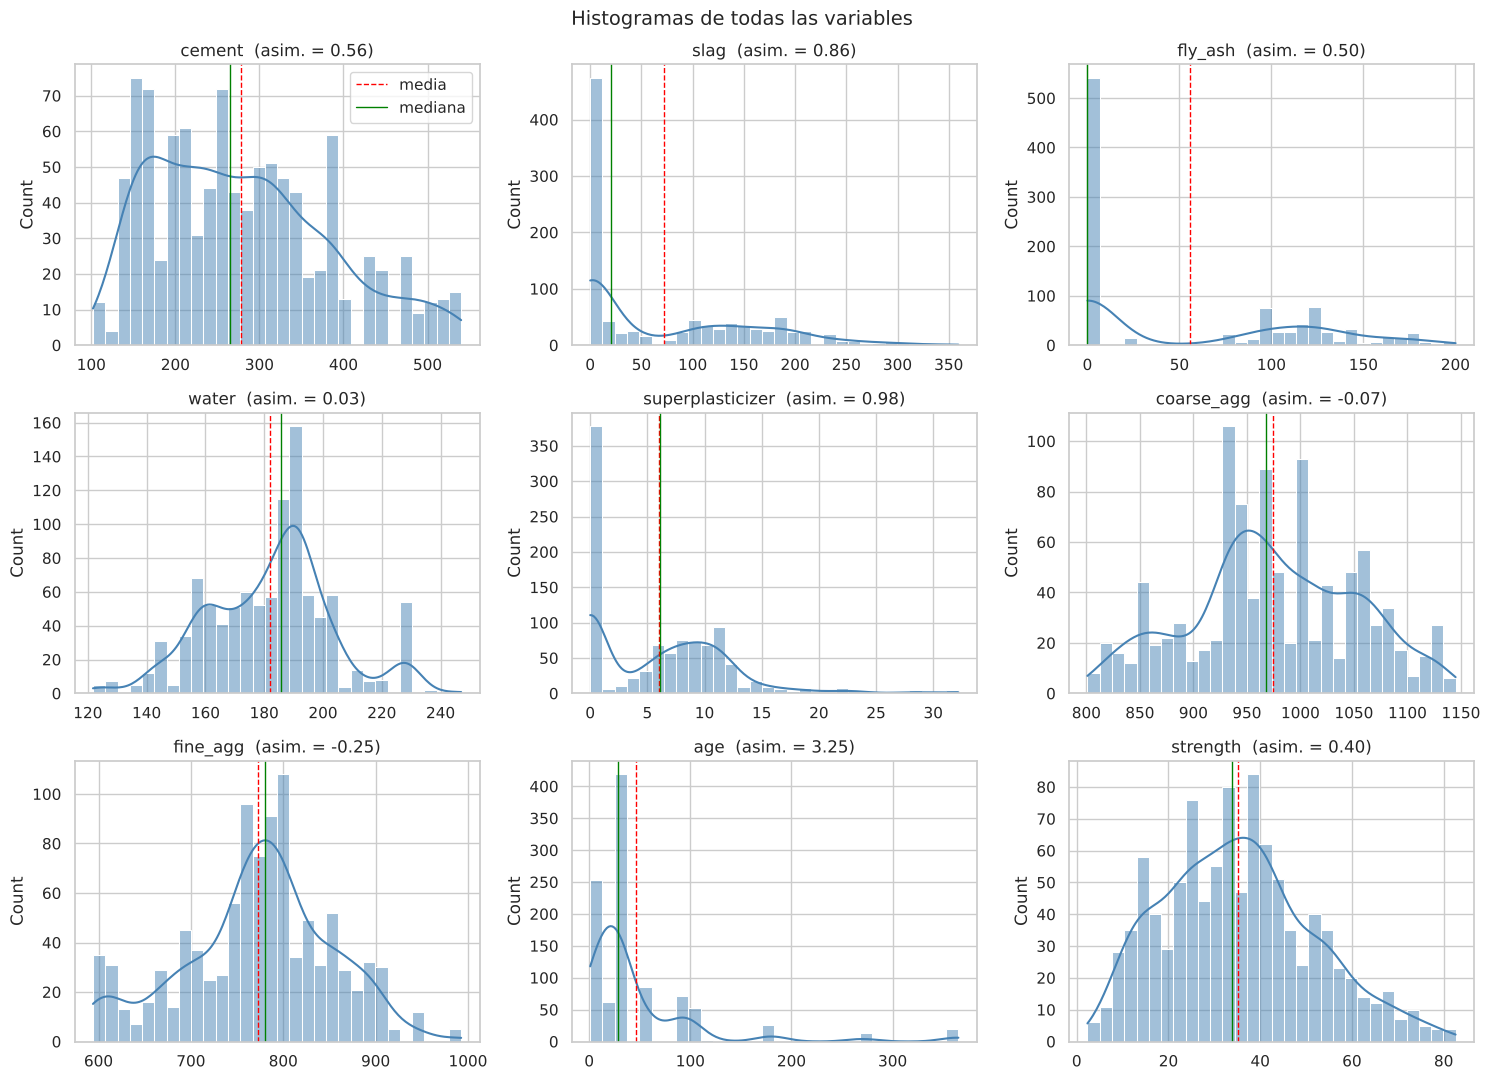

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue", bins=30)
    ax.axvline(df[col].mean(), color="red", ls="--", lw=1, label="media")
    ax.axvline(df[col].median(), color="green", ls="-", lw=1, label="mediana")
    ax.set_title(f"{col}  (asim. = {df[col].skew():.2f})")
    ax.set_xlabel("")
axes.flat[0].legend()
fig.suptitle("Histogramas de todas las variables", fontsize=14)
plt.tight_layout()
plt.show()

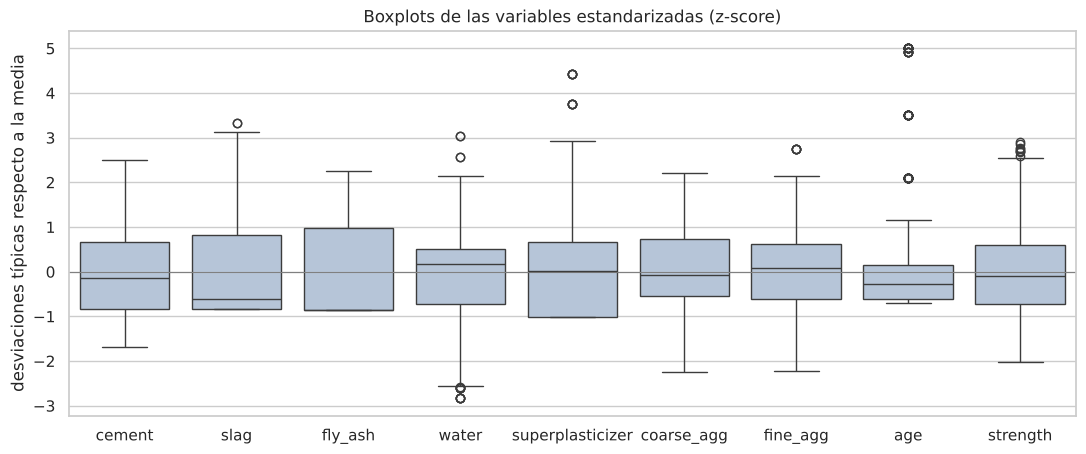

In [14]:
# Boxplots estandarizados (z-score) para poder comparar variables de escalas distintas en un solo gráfico
z = (df - df.mean()) / df.std()
plt.figure(figsize=(13, 5))
sns.boxplot(data=z, orient="v", color="lightsteelblue")
plt.axhline(0, color="grey", lw=0.8)
plt.title("Boxplots de las variables estandarizadas (z-score)")
plt.ylabel("desviaciones típicas respecto a la media")
plt.show()

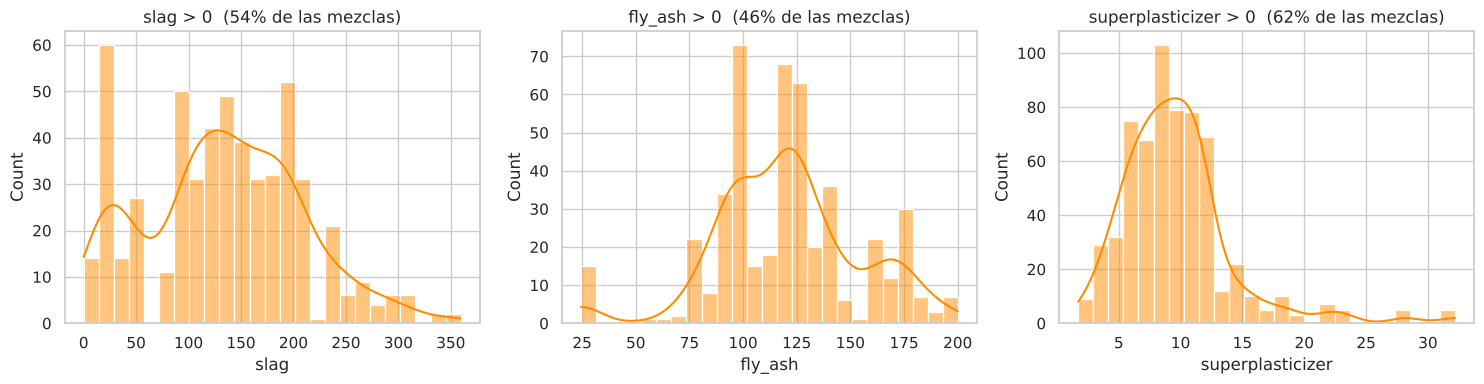

In [15]:
# Aditivos: proporción de mezclas que los usan y distribución cuando se usan
aditivos = ["slag", "fly_ash", "superplasticizer"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, aditivos):
    usados = df.loc[df[col] > 0, col]
    sns.histplot(usados, kde=True, ax=ax, bins=25, color="darkorange")
    ax.set_title(f"{col} > 0  ({len(usados) / len(df):.0%} de las mezclas)")
plt.tight_layout()
plt.show()

age,1,3,7,14,28,56,90,91,100,120,180,270,360,365
n,2.0,129.0,122.0,62.0,419.0,86.0,54.0,17.0,52.0,3.0,26.0,13.0,6.0,14.0
%,0.2,12.8,12.1,6.2,41.7,8.6,5.4,1.7,5.2,0.3,2.6,1.3,0.6,1.4


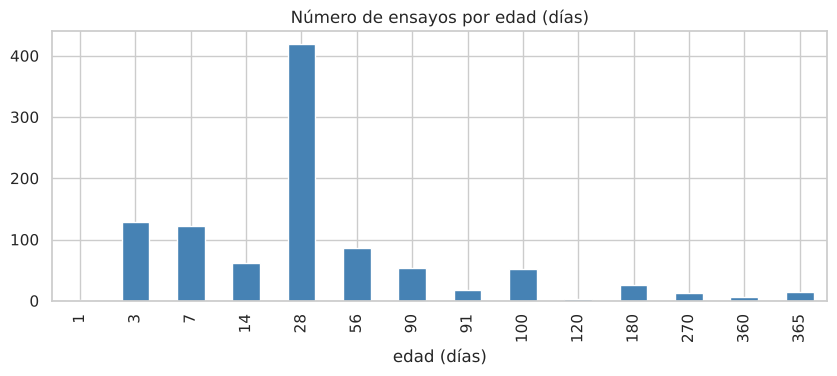

In [16]:
# La edad es en realidad una variable discreta: pocos valores muy repetidos
tabla_edad = df["age"].value_counts().sort_index().to_frame("n")
tabla_edad["%"] = (tabla_edad["n"] / len(df) * 100).round(1)
display(tabla_edad.T)

ax = tabla_edad["n"].plot.bar(figsize=(10, 3.5), color="steelblue")
ax.set_title("Número de ensayos por edad (días)")
ax.set_xlabel("edad (días)")
plt.show()

**Interpretación**

- **`strength`** tiene una distribución unimodal, aproximadamente simétrica con ligera cola a la derecha; la media y la
  mediana están muy próximas. No requiere transformación como variable objetivo.
- **`cement`** es asimétrica a la derecha, con más mezclas de dosificación baja-media que alta.
- **`slag`, `fly_ash` y `superplasticizer`** presentan un **pico enorme en 0** (distribución con *inflado de ceros*).
  Cuando se usan, la escoria y la ceniza muestran valores muy variados; el superplastificante se concentra entre 5 y 12 kg/m³.
  Para el modelado puede ser útil añadir **variables indicadoras** (`usa_slag`, `usa_fly_ash`, `usa_sp`).
- **`water`, `coarse_agg` y `fine_agg`** son las más cercanas a una distribución normal; el agua muestra varios picos
  (valores de dosificación habituales, p. ej. 192 y 228 kg/m³).
- **`age`** no es realmente continua: solo toma **14 valores distintos** y está dominada por los ensayos estándar a
  **28 días (≈ 41 %)**, seguidos de 3 y 7 días. Es fuertemente asimétrica, por lo que una **transformación logarítmica**
  (`log(age)`) sería adecuada para modelos lineales.
- En los boxplots estandarizados se ve que `age` es la variable con los atípicos más extremos (hasta ~5 σ), y que
  `superplasticizer` y `water` presentan algunos valores aislados.

## 5. Análisis bivariable / multivariable

Correlaciones entre componentes y resistencia.

> 📘 **Dos coeficientes de correlación:**
> - **Pearson**: mide relación **lineal**. Sensible a atípicos.
> - **Spearman**: mide relación **monótona** (usa rangos). Si Spearman ≫ Pearson, la relación existe pero **no es lineal**
>   (señal de que conviene transformar la variable). Compararlos es una forma sencilla de detectar no linealidad.
>
> Se lee: signo = dirección; |r| < 0,3 débil, 0,3–0,5 moderada, > 0,5 fuerte (orientativo).

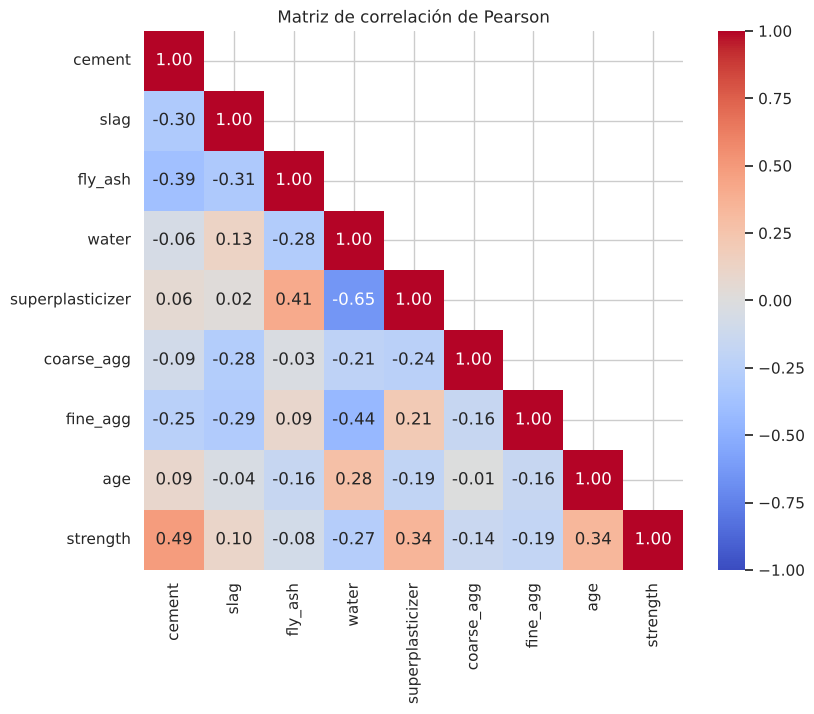

In [17]:
plt.figure(figsize=(9, 7))
corr = df.corr(method="pearson")
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlación de Pearson")
plt.show()

,Pearson,Spearman,diferencia
cement,0.49,0.46,-2.69e-02
superplasticizer,0.34,0.32,-2.24e-02
age,0.34,0.61,2.68e-01
water,-0.27,-0.28,-1.46e-02
fine_agg,-0.19,-0.19,-6.86e-03
coarse_agg,-0.14,-0.16,-1.81e-02
slag,0.10,0.14,3.53e-02
fly_ash,-0.08,-0.06,2.42e-02


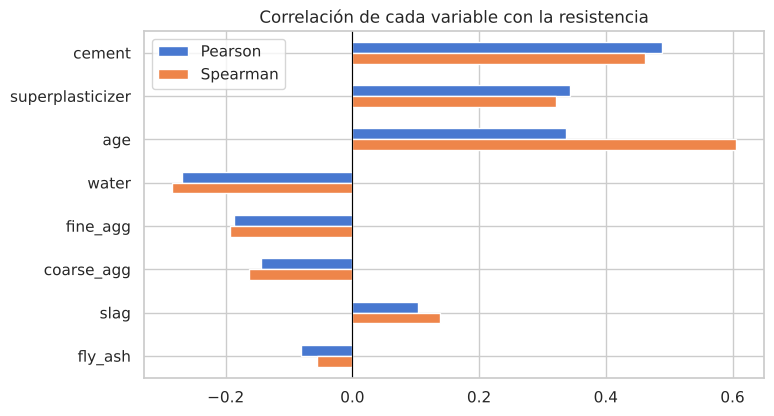

In [18]:
corr_obj = pd.DataFrame({
    "Pearson": df.corr(method="pearson")["strength"],
    "Spearman": df.corr(method="spearman")["strength"],
}).drop("strength")
corr_obj["diferencia"] = corr_obj["Spearman"] - corr_obj["Pearson"]
corr_obj = corr_obj.sort_values("Pearson", key=abs, ascending=False)
display(corr_obj)

corr_obj[["Pearson", "Spearman"]].plot.barh(figsize=(8, 4.5))
plt.axvline(0, color="black", lw=0.8)
plt.gca().invert_yaxis()
plt.title("Correlación de cada variable con la resistencia")
plt.show()

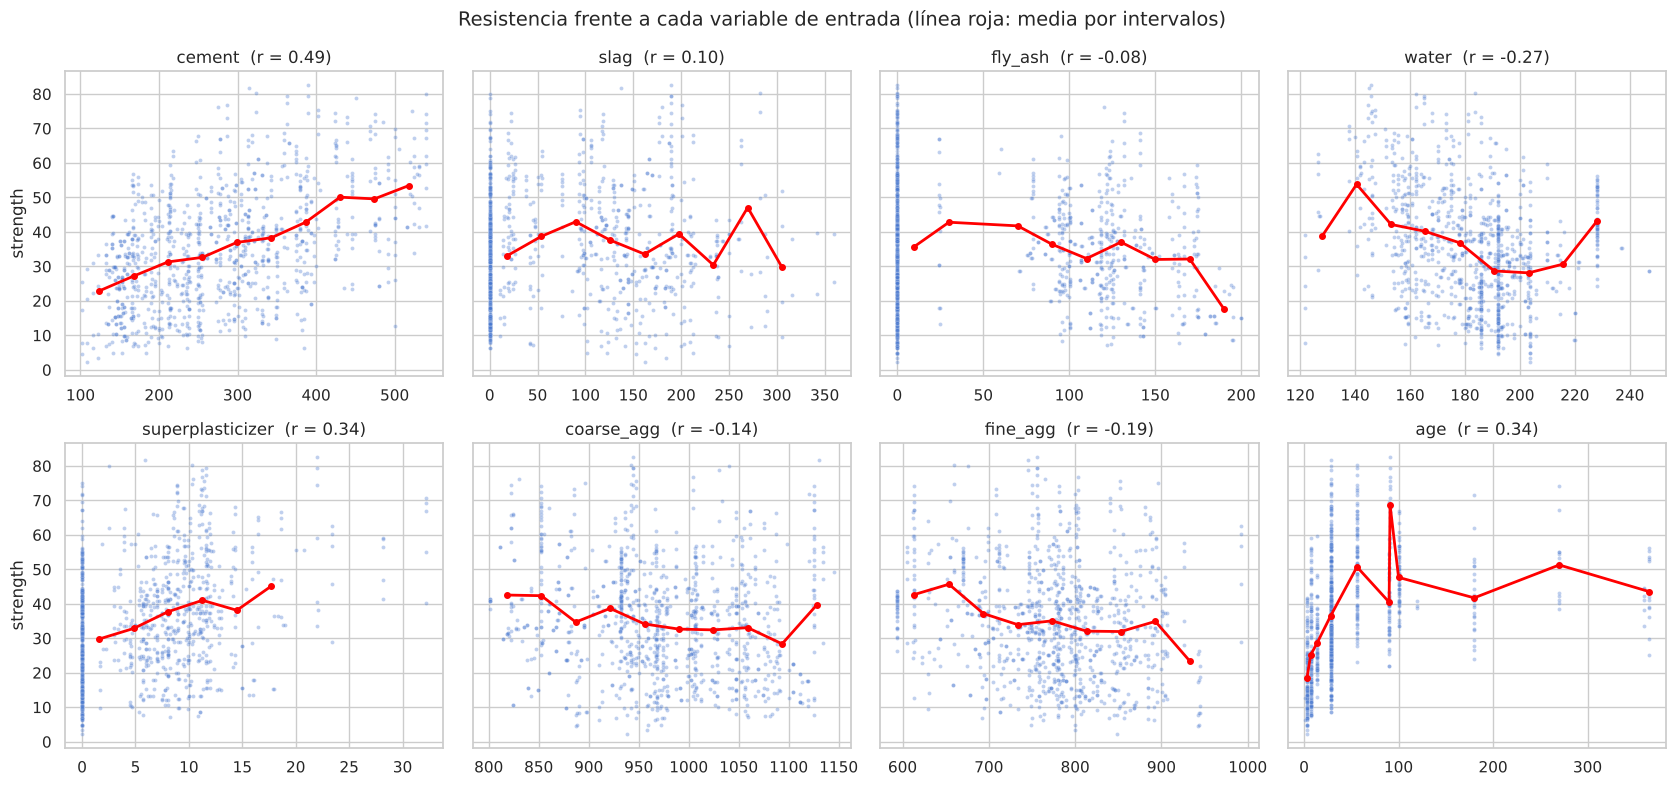

In [19]:
# Diagramas de dispersión de cada variable frente a la resistencia, con una línea de tendencia no lineal:
# se divide la variable en intervalos y se dibuja la resistencia media de cada intervalo
def tendencia_por_intervalos(x, y, n_bins=10, min_n=10):
    if x.nunique() <= 20:                       # variable casi discreta (age): media por valor
        grupos = y.groupby(x)
    else:
        grupos = y.groupby(pd.cut(x, bins=n_bins), observed=True)
    t = grupos.agg(["mean", "size"])
    t = t[t["size"] >= min_n]
    centros = [i.mid if isinstance(i, pd.Interval) else i for i in t.index]
    return centros, t["mean"].values

entradas = [c for c in df.columns if c != "strength"]
fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharey=True)
for ax, col in zip(axes.flat, entradas):
    sns.scatterplot(data=df, x=col, y="strength", ax=ax, s=8, alpha=0.35)
    cx, cy = tendencia_por_intervalos(df[col], df["strength"])
    ax.plot(cx, cy, color="red", lw=2, marker="o", ms=4)
    ax.set_title(f"{col}  (r = {corr_obj.loc[col, 'Pearson']:.2f})")
    ax.set_xlabel("")
fig.suptitle("Resistencia frente a cada variable de entrada (línea roja: media por intervalos)", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretación de las correlaciones con la resistencia**

- **Cemento** (r = 0,49): la relación **positiva más fuerte** entre los componentes y prácticamente lineal (Pearson ≈ Spearman).
  Más cemento → más resistencia, aunque con mucha dispersión: el cemento por sí solo no determina la resistencia.
- **Edad**: Pearson moderado (0,34) pero **Spearman claramente mayor (0,61)**. La relación es fuerte pero **no lineal**: la
  resistencia crece muy rápido los primeros días y se estabiliza a partir de ~56–90 días (la línea de tendencia es cóncava). Es la mejor
  prueba de que hace falta transformar la edad (p. ej. `log(age)`) o usar modelos no lineales.
- **Superplastificante** (0,34): positiva y moderada. La resistencia media crece de forma
  sostenida hasta ~10–12 kg/m³; por encima hay muy pocas mezclas, así que la tendencia en esa zona es poco fiable.
- **Agua** (−0,27): negativa. A más agua, menos resistencia, lo que concuerda con la ingeniería de materiales
  (el exceso de agua aumenta la porosidad del hormigón endurecido).
- **Escoria** (0,10), **ceniza volante** (−0,08), **árido grueso** (−0,14) y **árido fino** (−0,19): relaciones débiles. Las
  correlaciones débiles **no implican que sean irrelevantes**: pueden actuar en combinación con otras variables
  (p. ej. la ceniza volante sustituye parcialmente al cemento y aporta resistencia a largo plazo).

**Correlaciones entre componentes (multicolinealidad)**

- **Agua – superplastificante (r = −0,65)**: la más fuerte del dataset. Tiene sentido: el superplastificante se añade
  precisamente para **reducir la cantidad de agua** manteniendo la trabajabilidad. Esto implica que parte de la correlación
  positiva del superplastificante con la resistencia puede deberse, indirectamente, a que esas mezclas llevan menos agua.
- **Agua – árido fino (−0,44)**, **ceniza volante – superplastificante (0,41)** y **cemento – ceniza volante (−0,39)**: reflejan
  decisiones de dosificación (la ceniza y la escoria **sustituyen** parcialmente al cemento como aglomerante).
- Ningún par supera |r| = 0,7, así que la multicolinealidad es **moderada**; aun así conviene tenerla en cuenta al interpretar
  coeficientes de un modelo lineal.

### 5.1 Efecto de la edad

> 📘 Como `age` solo toma unos pocos valores, la tratamos como **categórica** para ver la distribución de la resistencia en
> cada edad con boxplots. Ojo: cada edad contiene **mezclas distintas**, así que la comparación entre edades está mezclada
> con el efecto de la composición (*confusión*). Para aislar el efecto de la edad usamos después las mezclas que se ensayaron
> a varias edades.

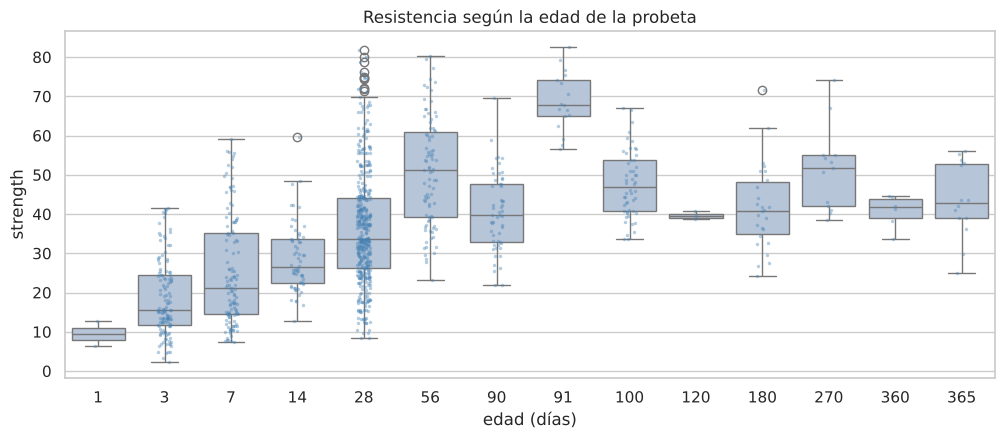

age,1,3,7,14,28,56,90,91,100,120,180,270,360,365
count,2.0,129.0,122.0,62.0,419.0,86.0,54.0,17.0,52.0,3.0,26.0,13.0,6.0,14.0
mean,9.5,18.4,25.2,28.8,36.4,50.7,40.5,68.7,47.7,39.6,41.7,51.3,40.7,43.6
median,9.5,15.5,21.2,26.5,33.7,51.1,39.7,67.8,47.0,39.4,40.9,51.7,41.7,42.8
std,4.5,9.6,14.0,8.6,14.4,13.7,9.8,7.5,8.4,1.1,10.9,10.6,4.2,9.6


In [20]:
plt.figure(figsize=(12, 4.5))
sns.boxplot(data=df, x="age", y="strength", color="lightsteelblue")
sns.stripplot(data=df, x="age", y="strength", color="steelblue", size=2.5, alpha=0.4)
plt.title("Resistencia según la edad de la probeta")
plt.xlabel("edad (días)")
plt.show()

df.groupby("age")["strength"].agg(["count", "mean", "median", "std"]).round(1).T

Mezclas distintas: 428 | ensayadas a 2 o más edades: 182


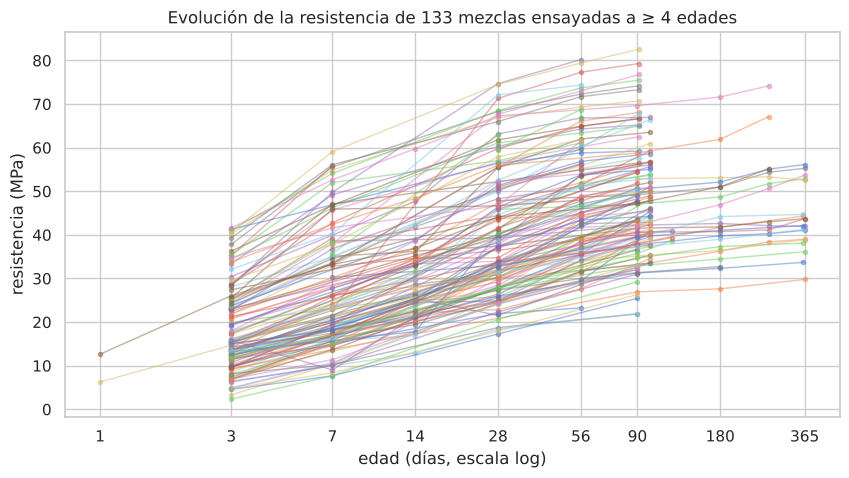

Correlación strength–age: Pearson = 0.34 | Pearson con log(age) = 0.56


In [21]:
# Seguimiento de las MISMAS mezclas a distintas edades (aísla el efecto de la edad)
mezcla_id = df.groupby(componentes, sort=False).ngroup()
edades_por_mezcla = df.groupby(mezcla_id)["age"].nunique()
print(f"Mezclas distintas: {mezcla_id.nunique()} | ensayadas a 2 o más edades: {(edades_por_mezcla > 1).sum()}")

seguidas = edades_por_mezcla[edades_por_mezcla >= 4].index
sub = df[mezcla_id.isin(seguidas)].assign(mezcla=mezcla_id)

fig, ax = plt.subplots(figsize=(10, 5))
for _, g in sub.groupby("mezcla"):
    g = g.sort_values("age")
    ax.plot(g["age"], g["strength"], marker="o", ms=3, lw=1, alpha=0.5)
ax.set_xscale("log")
ax.set_xticks([1, 3, 7, 14, 28, 56, 90, 180, 365])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel("edad (días, escala log)")
ax.set_ylabel("resistencia (MPa)")
ax.set_title(f"Evolución de la resistencia de {len(seguidas)} mezclas ensayadas a ≥ 4 edades")
plt.show()

print(f"Correlación strength–age: Pearson = {df['strength'].corr(df['age']):.2f} | "
      f"Pearson con log(age) = {df['strength'].corr(np.log(df['age'])):.2f}")

**Interpretación**

- La resistencia media **aumenta con la edad**: ~18 MPa a 3 días, ~25 a 7 días y ~36 a 28 días. Las medias por edad no son
  perfectamente monótonas (p. ej. 56 o 91 días superan a 90 o 365) porque **en cada edad se ensayaron mezclas diferentes**.
- Al seguir **las mismas mezclas** en el tiempo, el patrón es claro: la resistencia crece rápidamente durante el primer mes
  y después **se estabiliza** (curva de tipo logarítmico). En escala logarítmica la tendencia es casi lineal.
- Por ello, `log(age)` correlaciona con la resistencia bastante mejor que `age` (Pearson ≈ 0,56 frente a 0,34). Es una
  transformación recomendable.

### 5.2 Interacciones y variables derivadas: la relación agua/aglomerante

> 📘 En el EDA no solo se miran las variables originales: también se proponen **variables derivadas** con sentido de dominio
> (*feature engineering*). En hormigón la variable clásica es la **relación agua/cemento** (ley de Abrams: a menor relación, mayor
> resistencia). Como la escoria y la ceniza también actúan como aglomerantes, usamos además la relación
> **agua/aglomerante** = agua / (cemento + escoria + ceniza).

In [22]:
df_fe = df.copy()
df_fe["agua_cemento"] = df_fe["water"] / df_fe["cement"]
df_fe["agua_aglomerante"] = df_fe["water"] / (df_fe["cement"] + df_fe["slag"] + df_fe["fly_ash"])
df_fe["log_age"] = np.log(df_fe["age"])

nuevas = ["agua_cemento", "agua_aglomerante", "log_age", "cement", "age"]
pd.DataFrame({
    "Pearson": df_fe[nuevas].corrwith(df_fe["strength"]),
    "Spearman": df_fe[nuevas].corrwith(df_fe["strength"], method="spearman"),
}).sort_values("Pearson", key=abs, ascending=False)

,Pearson,Spearman
agua_aglomerante,-0.61,-0.59
log_age,0.56,0.61
agua_cemento,-0.49,-0.50
cement,0.49,0.46
age,0.34,0.61


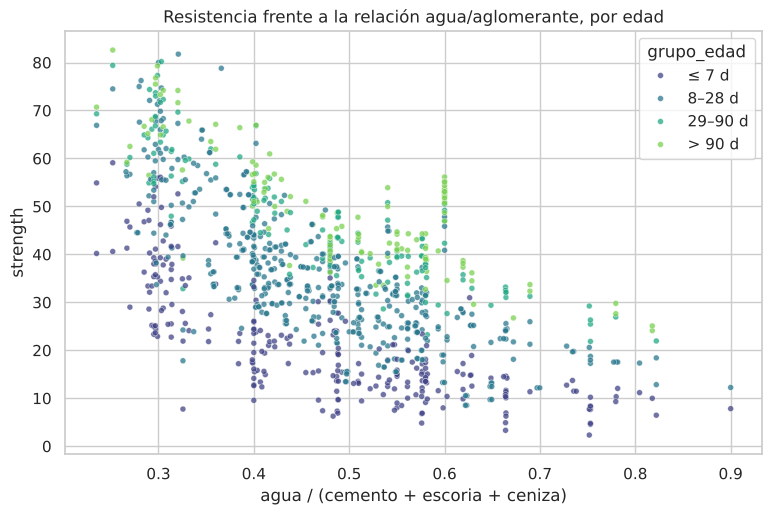

,count,mean,median
grupo_edad,,,
≤ 7 d,253,21.6,17.6
8–28 d,481,35.4,33.1
29–90 d,140,46.8,44.8
> 90 d,131,48.6,45.8


In [23]:
# Agua/aglomerante vs resistencia, coloreado por edad: dos efectos combinados
df_fe["grupo_edad"] = pd.cut(df_fe["age"], bins=[0, 7, 28, 90, 365],
                             labels=["≤ 7 d", "8–28 d", "29–90 d", "> 90 d"])
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df_fe, x="agua_aglomerante", y="strength", hue="grupo_edad",
                palette="viridis", s=18, alpha=0.75)
plt.title("Resistencia frente a la relación agua/aglomerante, por edad")
plt.xlabel("agua / (cemento + escoria + ceniza)")
plt.show()

df_fe.groupby("grupo_edad", observed=True)["strength"].agg(["count", "mean", "median"]).round(1)

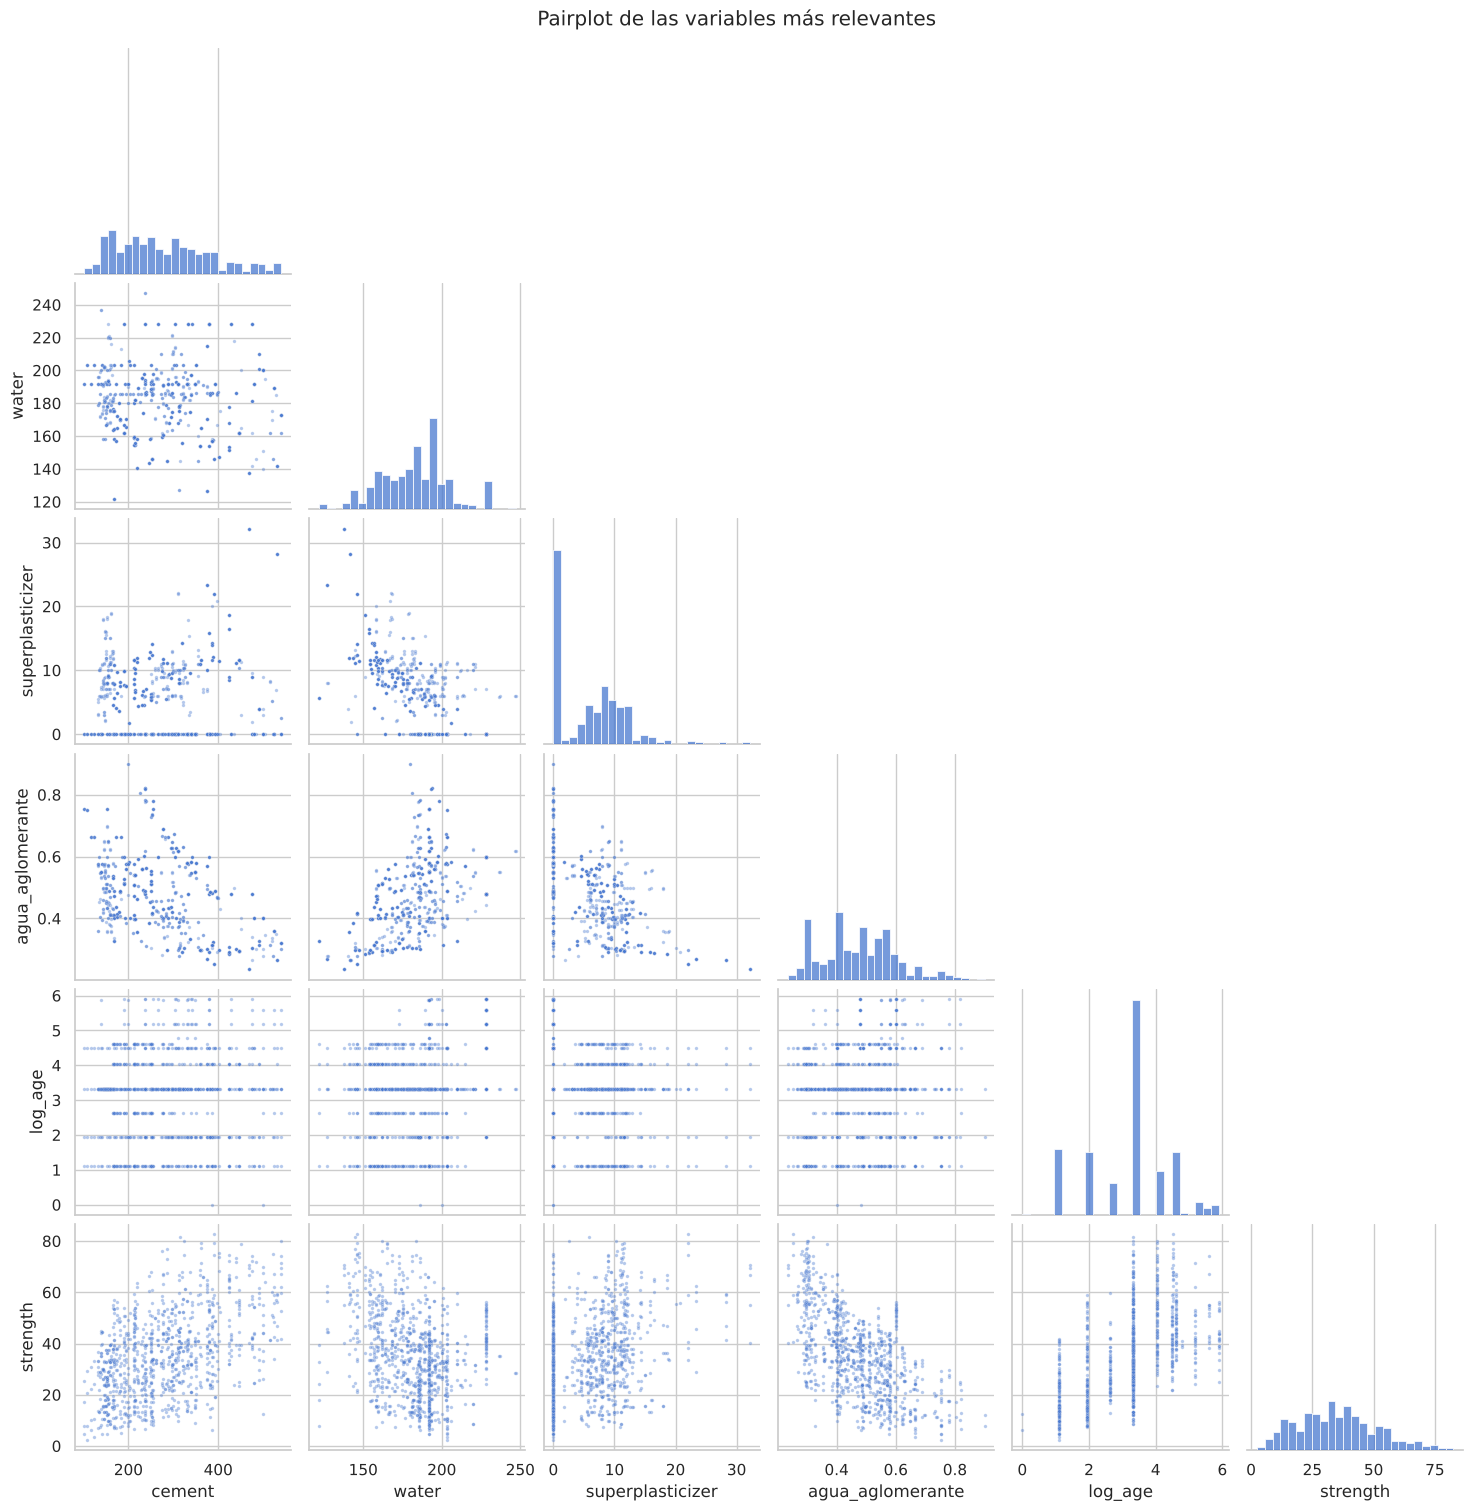

In [24]:
# Pairplot de las variables más relevantes (visión multivariable de conjunto)
sns.pairplot(df_fe[["cement", "water", "superplasticizer", "agua_aglomerante", "log_age", "strength"]],
             corner=True, plot_kws={"s": 6, "alpha": 0.4}, diag_kws={"bins": 25})
plt.suptitle("Pairplot de las variables más relevantes", y=1.01)
plt.show()

,strength,water,agua_aglomerante
usa_sp,,,
con SP,38.69,173.46,0.42
sin SP,29.54,196.37,0.55


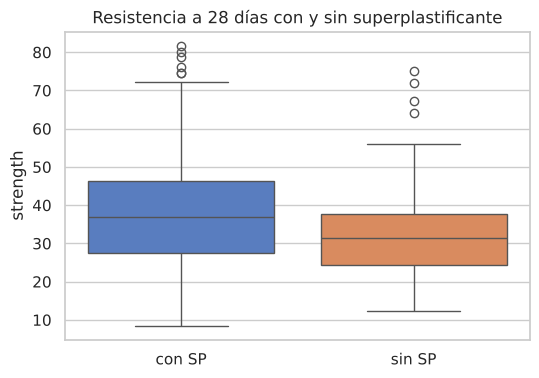

In [25]:
# ¿Influye usar o no superplastificante? (comparando también a igualdad de edad, 28 días)
df_fe["usa_sp"] = np.where(df_fe["superplasticizer"] > 0, "con SP", "sin SP")
display(df_fe.groupby("usa_sp")[["strength", "water", "agua_aglomerante"]].mean().round(2))

plt.figure(figsize=(6, 4))
sns.boxplot(data=df_fe[df_fe["age"] == 28], x="usa_sp", y="strength", hue="usa_sp", legend=False)
plt.title("Resistencia a 28 días con y sin superplastificante")
plt.xlabel("")
plt.show()

**Interpretación multivariable**

- La **relación agua/aglomerante** es la variable **más correlacionada con la resistencia** de todo el análisis
  (Pearson ≈ −0,61), por encima de cualquier componente individual, y mejora también a la relación agua/cemento (≈ −0,49).
  Confirma la ley de Abrams: lo que importa no es la cantidad absoluta de cada ingrediente, sino **sus proporciones**.
- En el gráfico coloreado por edad se ven **dos efectos que se suman**: a igual relación agua/aglomerante, las probetas más
  antiguas son más resistentes; y a igual edad, menos agua relativa implica más resistencia. La resistencia depende
  **conjuntamente** de la dosificación y del tiempo de curado, lo que justifica el comentario del Readme sobre su carácter
  "altamente no lineal".
- Las mezclas **con superplastificante** son de media ~9 MPa más resistentes (38,7 frente a 29,5 MPa), pero también llevan **menos agua** y una relación
  agua/aglomerante menor: el superplastificante actúa principalmente **permitiendo reducir el agua**. Es un ejemplo de
  por qué una correlación bivariable no debe interpretarse como causalidad directa sin mirar las demás variables.

## 6. Conclusiones e insights

1. **Calidad de los datos.** 1030 registros, 9 variables numéricas y ningún nulo. Se eliminaron **25 duplicados exactos**
   (quedan 1005). La masa total por m³ es físicamente coherente. Los atípicos detectados (sobre todo edades de 180–365 días y
   hormigones de alta resistencia) son valores reales y **se conservan**.
2. **Variable objetivo.** La resistencia (media 35,8 MPa, rango 2,3–82,6 MPa) tiene una distribución aproximadamente simétrica;
   el problema es de **regresión** y no requiere transformar el objetivo.
3. **Distribuciones particulares.** Escoria, ceniza volante y superplastificante tienen un 37–55 % de **ceros** (aditivos
   opcionales); la edad es **discreta y muy asimétrica**, dominada por los ensayos a 28 días.
4. **Factores más relacionados con la resistencia**: la **edad** (relación fuerte y no lineal, Spearman 0,61), el **cemento**
   (+0,49), el **superplastificante** (+0,34) y el **agua** (−0,27). Los áridos, la escoria y la ceniza tienen relaciones
   individuales débiles.
5. **Las proporciones importan más que las cantidades.** La **relación agua/aglomerante** (r ≈ −0,61) es el mejor predictor
   individual, de acuerdo con la ley de Abrams.
6. **Relaciones entre componentes.** La correlación agua–superplastificante (−0,65) y las sustituciones cemento–aditivos reflejan
   el diseño de las mezclas. Hay multicolinealidad moderada (|r| < 0,7).
7. **Implicaciones para el modelado**:
   - Incluir variables derivadas (`agua/aglomerante`, `log(age)`, indicadores de uso de aditivos).
   - **Estandarizar** las variables (escalas muy distintas).
   - La relación es **no lineal**: se esperan mejores resultados con modelos no lineales (árboles, *random forest*,
     *gradient boosting*, redes neuronales) que con una regresión lineal sobre las variables originales.
   - Como muchas mezclas se ensayaron a varias edades, en la validación convendría **agrupar por mezcla** (p. ej. `GroupKFold`)
     para evitar que la misma mezcla aparezca en entrenamiento y test.

> 📘 **Resumen de herramientas usadas en la Parte 2** (para repasar): `describe()` + varianza, CV, asimetría y curtosis →
> criterio IQR para atípicos → histogramas/KDE y boxplots → heatmap de correlaciones (Pearson y Spearman) → scatter con línea de tendencia →
> boxplots por grupos → variables derivadas → pairplot. Compáralo con la Parte 1, donde todo era categórico
> (frecuencias, crosstab, χ² y V de Cramér).